In [1]:
import numpy as np
import os
import json
import pandas as pd
import math 
from pyscf import scf

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]
plt.rcParams['font.size'] = 14

In [2]:
init_strategies = [
    'minao',
    '1e',
    'atom',
    'huckel',
    'vsap',
    'sap'
]

basis_sets = [
    'cc-pVDZ',
    'cc-pVTZ',
    'cc-pVQZ',
]

scf_methods = ["rohf", "so-rohf"]

In [3]:
simulation_cost = {
    'cc-pVDZ': {"n_qubits": None, "nelec": None},
    'cc-pVTZ': {"n_qubits": None, "nelec": None},
    'cc-pVQZ': {"n_qubits": None, "nelec": None},
}

results_ROHF_new = {
    'cc-pVDZ': [],
    'cc-pVTZ': [],
    'cc-pVQZ': [],
}

results_ROHF_pyscf = {
    'cc-pVDZ': [],
    'cc-pVTZ': [],
    'cc-pVQZ': [],
}


results_SO_ROHF_new = {
    'cc-pVDZ': [],
    'cc-pVTZ': [],
    'cc-pVQZ': [],
}

results_SO_ROHF_pyscf = {
    'cc-pVDZ': [],
    'cc-pVTZ': [],
    'cc-pVQZ': [],
}


for basis in basis_sets:
    data_path = os.path.join(os.getcwd(), basis)
    qubo_data_dir = os.path.join(data_path, "QUBO")
    for scf_method in scf_methods:
        for init_method in init_strategies:
            input_string = f"{basis}_{init_method}_{scf_method}"
            

            qubo_path = os.path.join(qubo_data_dir, input_string + '.json')
            with open(qubo_path, 'r') as infile:
                qubo_dict = json.load(infile)

            

            # qubo_dict keys are: ['Qubo_matrix', 'constant_shift', 'n_qubits', 'nelec', 'HF_soln', 'alternate_soln']
            qubo_M = np.array(qubo_dict["Qubo_matrix"])
            constant_shift = qubo_dict["constant_shift"] 
            alternate_soln = np.array(qubo_dict["alternate_soln"], dtype=np.int8)

            # HF_soln = np.array(qubo_dict["HF_soln"], dtype=np.int8) 
            chkfile = os.path.join(data_path, input_string + ".chk")
            mol = scf.chkfile.load_mol(chkfile)
            global_scf = scf.ROHF(mol) 
            global_scf.__dict__.update(scf.chkfile.load(chkfile, 'scf'))
            HF_soln =  np.vstack((global_scf.mo_occ>1 , global_scf.mo_occ>0 )).T.reshape(-1).astype(np.int8)

            hf_val  = np.einsum("i,ij,j->", HF_soln,qubo_M,HF_soln) + constant_shift
            new_val = np.einsum("i,ij,j->", alternate_soln,qubo_M,alternate_soln) + constant_shift

            # print(hf_val, new_val, new_val < hf_val)

            if scf_method == "rohf":
                results_ROHF_new[basis].append(new_val)
                results_ROHF_pyscf[basis].append(hf_val)
                
            elif scf_method == "so-rohf":
                results_SO_ROHF_new[basis].append(new_val)
                results_SO_ROHF_pyscf[basis].append(hf_val)
            
            simulation_cost[basis]["n_qubits"] = qubo_dict["n_qubits"]
            simulation_cost[basis]["nelec"]    = qubo_dict["nelec"]
            

In [4]:
dz_results = np.array(results_ROHF_new['cc-pVDZ']) - np.array(results_ROHF_pyscf['cc-pVDZ'])
tz_results = np.array(results_ROHF_new['cc-pVTZ']) - np.array(results_ROHF_pyscf['cc-pVTZ'])
qz_results = np.array(results_ROHF_new['cc-pVQZ']) - np.array(results_ROHF_pyscf['cc-pVQZ'])


dz_results_SO = np.array(results_SO_ROHF_new['cc-pVDZ']) - np.array(results_SO_ROHF_pyscf['cc-pVDZ'])
tz_results_SO = np.array(results_SO_ROHF_new['cc-pVTZ']) - np.array(results_SO_ROHF_pyscf['cc-pVTZ'])
qz_results_SO = np.array(results_SO_ROHF_new['cc-pVQZ']) - np.array(results_SO_ROHF_pyscf['cc-pVQZ'])


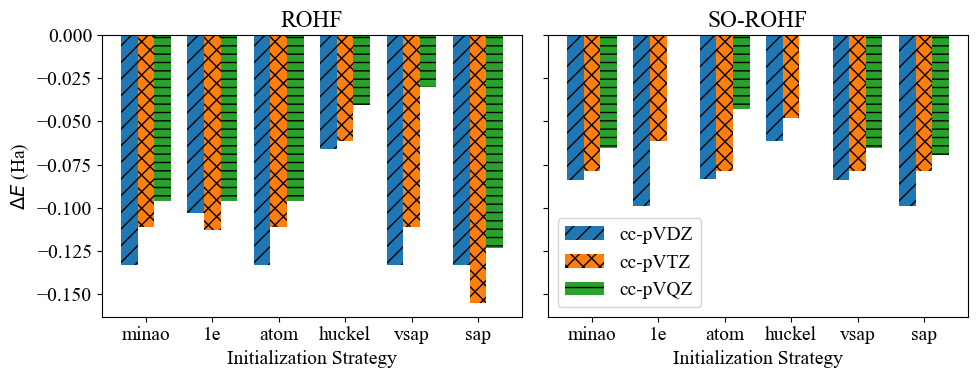

In [8]:
x_positions = np.arange(len(init_strategies))

# Create a figure with 1 row and 2 columns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

width = 0.25 # Width of each individual bar
rects1 = ax1.bar(x_positions - width, dz_results, width, label='cc-pVDZ', hatch="//")
rects2 = ax1.bar(x_positions, tz_results, width, label='cc-pVTZ', hatch="xx")
rects3 = ax1.bar(x_positions + width, qz_results, width, label='cc-pVQZ', hatch="--")


ax1.set_xticks(x_positions)
ax1.set_xticklabels(init_strategies)

ax1.set_title('ROHF')
ax1.set_xlabel('Initialization Strategy')
ax1.set_ylabel(r'$\Delta E$ (Ha)')


rects1 = ax2.bar(x_positions - width, dz_results_SO, width, label='cc-pVDZ', hatch="//")
rects2 = ax2.bar(x_positions, tz_results_SO, width, label='cc-pVTZ', hatch="xx")
rects3 = ax2.bar(x_positions + width, qz_results_SO, width, label='cc-pVQZ', hatch="--")


ax2.set_xticks(x_positions)
ax2.set_xticklabels(init_strategies)

ax2.set_title('SO-ROHF')
ax2.set_xlabel('Initialization Strategy')
# ax2.set_ylabel(r'$\Delta E$ (Ha)')

ax2.legend()

plt.tight_layout()
fig.savefig('O3-results.png', dpi=300)


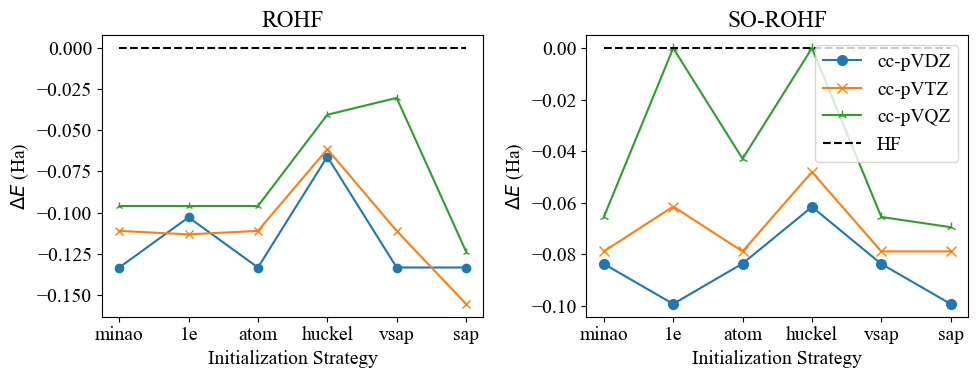

In [9]:
x_positions = list(range(len(init_strategies)))

# Create a figure with 1 row and 2 columns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Plot on the first graph (Left)
ax1.plot(x_positions, dz_results, marker='o', label='cc-pVDZ')
ax1.plot(x_positions, tz_results, marker='x', label='cc-pVTZ')
ax1.plot(x_positions, qz_results, marker='2', label='cc-pVQZ')

ax1.set_xticks(x_positions)
ax1.set_xticklabels(init_strategies)

ax1.hlines(y=0, xmin=x_positions[0],xmax=x_positions[-1], color='black', linestyle='--', label='HF')

ax1.set_title('ROHF')
ax1.set_xlabel('Initialization Strategy')
ax1.set_ylabel(r'$\Delta E$ (Ha)')


ax2.plot(x_positions, dz_results_SO, marker='o', label='cc-pVDZ', markersize=7)
ax2.plot(x_positions, tz_results_SO, marker='x', label='cc-pVTZ', markersize=7)
ax2.plot(x_positions, qz_results_SO, marker='2', label='cc-pVQZ', markersize=7)

ax2.hlines(y=0, xmin=x_positions[0],xmax=x_positions[-1], color='black', linestyle='--', label='HF')

ax2.set_xticks(x_positions)
ax2.set_xticklabels(init_strategies)

ax2.set_title('SO-ROHF')
ax2.set_xlabel('Initialization Strategy')
ax2.set_ylabel(r'$\Delta E$ (Ha)')

ax2.legend()

plt.tight_layout()
fig.savefig('O3-results-scatter.png', dpi=300)

In [10]:
rohf_results = pd.DataFrame({
    'cc-pVDZ': dz_results,
    'cc-pVTZ': tz_results,
    'cc-pVQZ': qz_results,
})
rohf_results.index = init_strategies
rohf_results

,cc-pVDZ,cc-pVTZ,cc-pVQZ
minao,-0.133417,-0.111145,-0.096022
1e,-0.102889,-0.113272,-0.096023
atom,-0.133414,-0.111131,-0.096023
huckel,-0.066024,-0.061446,-0.040510
vsap,-0.133417,-0.111145,-0.030269
sap,-0.133414,-0.155568,-0.123688


In [11]:
rohf_latex_code = rohf_results.to_latex(index=True)
print(rohf_latex_code)

\begin{tabular}{lrrr}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
minao & -0.133417 & -0.111145 & -0.096022 \\
1e & -0.102889 & -0.113272 & -0.096023 \\
atom & -0.133414 & -0.111131 & -0.096023 \\
huckel & -0.066024 & -0.061446 & -0.040510 \\
vsap & -0.133417 & -0.111145 & -0.030269 \\
sap & -0.133414 & -0.155568 & -0.123688 \\
\bottomrule
\end{tabular}



In [12]:
SO_rohf_results = pd.DataFrame({
    'cc-pVDZ': dz_results_SO,
    'cc-pVTZ': tz_results_SO,
    'cc-pVQZ': qz_results_SO,
})
SO_rohf_results.index = init_strategies
SO_rohf_results

,cc-pVDZ,cc-pVTZ,cc-pVQZ
minao,-0.083761,-0.078899,-0.065517
1e,-0.099283,-0.061475,0.000000
atom,-0.083609,-0.078899,-0.042935
huckel,-0.061620,-0.048055,0.000000
vsap,-0.083761,-0.078899,-0.065517
sap,-0.099283,-0.078898,-0.069503


In [46]:
SO_rohf_latex_code = SO_rohf_results.to_latex(index=True)
print(SO_rohf_latex_code)

\begin{tabular}{lrrr}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
minao & -0.083761 & -0.078899 & -0.065517 \\
1e & -0.099283 & -0.061475 & 0.000000 \\
atom & -0.083609 & -0.078899 & -0.042935 \\
huckel & -0.061620 & -0.048055 & 0.000000 \\
vsap & -0.083761 & -0.078899 & -0.065517 \\
sap & -0.099283 & -0.078898 & -0.069503 \\
\bottomrule
\end{tabular}



In [14]:
for basis in basis_sets:
    n_spatial_orbs = simulation_cost[basis]['n_qubits']//2
    n_alpha, n_beta = simulation_cost[basis]['nelec']
    search_space = math.comb(n_spatial_orbs, n_alpha) * math.comb(n_spatial_orbs, n_beta)
    print(f"{basis} search space: {search_space:.4e} \t ({n_spatial_orbs}, {n_alpha})*({n_spatial_orbs}, {n_beta})")


cc-pVDZ search space: 1.0923e+20 	 (42, 13)*(42, 11)
cc-pVTZ search space: 6.8373e+28 	 (90, 13)*(90, 11)
cc-pVQZ search space: 2.9211e+35 	 (165, 13)*(165, 11)


# load seperate results

In [23]:
## keys to change
basis = 'cc-pVTZ'
init_method = '1e'
scf_method = 'so-rohf'
##

data_path = os.path.join(os.getcwd(), basis)
qubo_data_dir = os.path.join(data_path, "QUBO")
input_string = f"{basis}_{init_method}_{scf_method}"
qubo_path = os.path.join(qubo_data_dir, input_string + '.json')
with open(qubo_path, 'r') as infile:
    qubo_dict = json.load(infile)

# qubo_dict keys are: ['Qubo_matrix', 'constant_shift', 'n_qubits', 'nelec', 'HF_soln', 'alternate_soln']
qubo_M = np.array(qubo_dict["Qubo_matrix"])
constant_shift = qubo_dict["constant_shift"] 
alternate_soln = np.array(qubo_dict["alternate_soln"], dtype=np.int8)

# HF_soln = np.array(qubo_dict["HF_soln"], dtype=np.int8) 
chkfile = os.path.join(data_path, input_string + ".chk")
mol = scf.chkfile.load_mol(chkfile)
global_scf = scf.ROHF(mol) 
global_scf.__dict__.update(scf.chkfile.load(chkfile, 'scf'))
HF_soln =  np.vstack((global_scf.mo_occ>1 , global_scf.mo_occ>0 )).T.reshape(-1).astype(np.int8)

hf_val  = np.einsum("i,ij,j->", HF_soln,qubo_M,HF_soln) + constant_shift
new_val = np.einsum("i,ij,j->", alternate_soln,qubo_M,alternate_soln) + constant_shift

print("Ordering is alpha, beta, alpha, beta, ...etc")
print("HF solution: ", HF_soln)
print("NEW solution: ", alternate_soln)

Ordering is alpha, beta, alpha, beta, ...etc
HF solution:  [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
NEW solution:  [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
## get molecular info from pyscf
print("structure")
print(mol.tostring(format='xyz'))
print("\n")
print(f"basis: {mol.basis}")
print(f"charge: {mol.charge}")
print(f"spin (2S): {mol.spin}")
print(f"number spatial orbitals: {mol.nao}")

structure
3
XYZ from PySCF
O           0.00000000        0.00000000        0.00000000
O           0.00000000        0.00000000        2.00000000
O           0.00000000        0.00000000        4.00000000


basis: cc-pVTZ
charge: 0
spin (2S): 2
number spatial orbitals: 90


In [25]:
print("pyscf chk result      :", global_scf.e_tot)

rdm_pyscf = global_scf.make_rdm1(mo_occ = HF_soln[0::2] + HF_soln[1::2])
print("pyscf QUBO result     :", global_scf.energy_tot(dm=rdm_pyscf))
print("above results should match up to floating point precision \n")

rdm_custom = global_scf.make_rdm1(mo_occ = alternate_soln[0::2] + alternate_soln[1::2])
print("alternate QUBO result :", global_scf.energy_tot(dm=rdm_custom))


pyscf chk result      : -224.19363384335597
pyscf QUBO result     : -224.19363384335603
above results should match up to floating point precision 

alternate QUBO result : -224.28508388821942


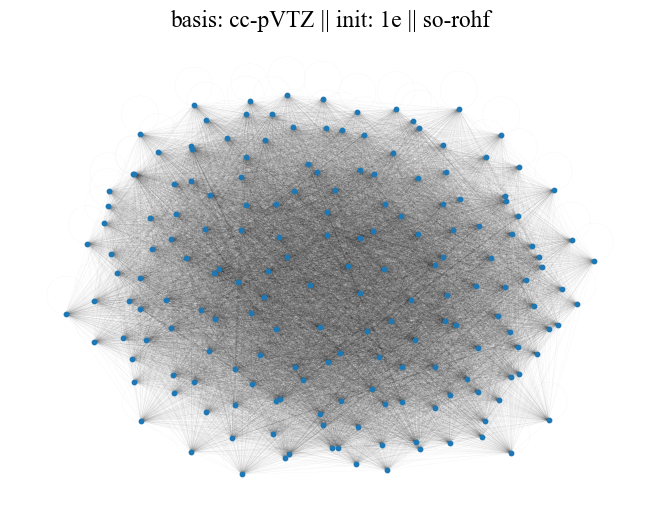

In [26]:
### VIEW QUBO GRAPH if desired:
import networkx as nx

G_qubo = nx.from_numpy_array(qubo_M)
nx.draw(G_qubo, node_size=10, width=0.01)

plt.title(f"basis: {basis} || init: {init_method} || {scf_method}")
plt.show()

In [ ]:
## SCF CONVERGENCE AND STABILITY

stability_std = {
    'cc-pVDZ': [],
    'cc-pVTZ': [],
    'cc-pVQZ': [],
}

stability_so = {
    'cc-pVDZ': [],
    'cc-pVTZ': [],
    'cc-pVQZ': [],
}

meta_data_path = os.path.join(os.getcwd(), 'metadata.json')
with open(meta_data_path, 'r') as infile:
    meta_data = json.load(infile)

for basis in basis_sets:
    for init_method in init_strategies:
        conv_std = meta_data[basis][init_method]['rohf']['has_converged']
        internal_stability_std = meta_data[basis][init_method]['rohf']['internal_stability']
        stability_std[basis].append((conv_std, internal_stability_std))

        conv_so = meta_data[basis][init_method]['so-rohf']['has_converged']
        internal_stability_so = meta_data[basis][init_method]['so-rohf']['internal_stability']
        stability_so[basis].append((conv_so, internal_stability_so))
        



In [39]:
stability_std_df = pd.DataFrame(stability_std)
stability_so_df = pd.DataFrame(stability_so)

stability_std_df.index = init_strategies
stability_so_df.index = init_strategies

In [ ]:
# key: (converged, internally stable)
stability_std_df

,cc-pVDZ,cc-pVTZ,cc-pVQZ
minao,"(True, False)","(True, False)","(True, False)"
1e,"(True, True)","(True, False)","(True, False)"
atom,"(True, False)","(True, False)","(True, False)"
huckel,"(True, True)","(True, True)","(True, True)"
vsap,"(True, False)","(True, False)","(True, False)"
sap,"(True, False)","(True, True)","(True, True)"


In [44]:
stability_so_df

,cc-pVDZ,cc-pVTZ,cc-pVQZ
minao,"(True, True)","(True, True)","(True, True)"
1e,"(True, True)","(True, True)","(True, True)"
atom,"(True, True)","(True, True)","(True, True)"
huckel,"(True, True)","(True, True)","(True, True)"
vsap,"(True, True)","(True, True)","(True, True)"
sap,"(True, True)","(True, True)","(True, True)"


In [43]:
print(stability_std_df.to_latex())

\begin{tabular}{llll}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
minao & (True, False) & (True, False) & (True, False) \\
1e & (True, True) & (True, False) & (True, False) \\
atom & (True, False) & (True, False) & (True, False) \\
huckel & (True, True) & (True, True) & (True, True) \\
vsap & (True, False) & (True, False) & (True, False) \\
sap & (True, False) & (True, True) & (True, True) \\
\bottomrule
\end{tabular}



In [45]:
print(stability_so_df.to_latex())

\begin{tabular}{llll}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
minao & (True, True) & (True, True) & (True, True) \\
1e & (True, True) & (True, True) & (True, True) \\
atom & (True, True) & (True, True) & (True, True) \\
huckel & (True, True) & (True, True) & (True, True) \\
vsap & (True, True) & (True, True) & (True, True) \\
sap & (True, True) & (True, True) & (True, True) \\
\bottomrule
\end{tabular}

